# 03 Estratégia e demonstração do Tech Challenge

Vamos usar o baseline do notebook 02 para demonstrar **bloqueio de dados
inválidos, Data Drift e Concept Drift simulado**, gerar relatórios HTML
com Evidently e registrar a execução em logs JSON e no MLflow.

Ao final, consolidamos a estratégia de resposta, governança e entrega.
Execute o notebook 02 antes deste. Os dados e modelos são locais; nenhum
serviço externo é necessário. A documentação final e o vídeo ainda devem
ser entregues conforme o [enunciado](../docs/MLET%20-%20Tech%20Challenge%20-%20Fase%204.pdf).

## 1 Recuperar o baseline e os conjuntos reservados

Os hashes impedem combinar acidentalmente um manifesto com um CSV ou modelo
de outra execução. O modelo carregado permanece congelado durante os cenários.
A referência é o treino; a produção contém somente os IDs reservados no notebook 02.

In [1]:
import hashlib
import json
import logging
import sys
from datetime import UTC, datetime
from pathlib import Path
from time import perf_counter

import evidently
import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import pandera.pandas as pa
from evidently import DataDefinition, Dataset, Report
from evidently.presets import DataDriftPreset
from IPython.display import Markdown, display

/opt/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
project_root = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "requirements.txt").is_file()
        and (folder / "notebooks").is_dir()
        and (folder / "ml_prep_kit").is_dir()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("Abra o notebook dentro da pasta do projeto.")

raw_path = project_root / "data" / "raw" / "home-credit-default-risk"
train_file = raw_path / "application_train.csv"
if not train_file.is_file():
    raise FileNotFoundError(f"Arquivo de treinamento não encontrado: {train_file}")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from ml_prep_kit import ModelEvaluator, StructuredJsonFormatter

processed_path = project_root / "data" / "processed"
dataset_file = processed_path / "credit_scoring.csv"
pipeline_file = processed_path / "model" / "baseline.joblib"
manifest_file = processed_path / "model" / "manifest.json"
for path in [dataset_file, pipeline_file, manifest_file]:
    if not path.is_file():
        raise FileNotFoundError(f"Execute o notebook 02 primeiro. Falta: {path.name}")
manifest = json.loads(manifest_file.read_text(encoding="utf-8"))
for path, hash_key in [
    (dataset_file, "dataset_sha256"),
    (pipeline_file, "pipeline_sha256"),
]:
    with path.open("rb") as stream:
        actual_hash = hashlib.file_digest(stream, "sha256").hexdigest()
    if actual_hash != manifest[hash_key]:
        raise ValueError(
            f"Artefato inconsistente: {path.name}. Reexecute o notebook 02."
        )

dataset = pd.read_csv(dataset_file)
pipeline = joblib.load(pipeline_file)
features = manifest["features"]
threshold = manifest["threshold"]
reference = dataset.loc[
    dataset["SK_ID_CURR"].isin(manifest["partitions"]["treino"])
].copy()
production = dataset.loc[
    dataset["SK_ID_CURR"].isin(manifest["partitions"]["producao"])
].copy()
assert len(reference) == len(manifest["partitions"]["treino"])
assert len(production) == len(manifest["partitions"]["producao"])
assert set(reference["SK_ID_CURR"]).isdisjoint(production["SK_ID_CURR"])
display(
    pd.DataFrame(manifest["test_metrics"]).T[
        ["roc_auc", "average_precision", "recall", "precision", "f1", "threshold"]
    ]
)
print(f"Referência: {len(reference):,}; produção: {len(production):,} registros.")

,roc_auc,average_precision,recall,precision,f1,threshold
dummy,0.500000,0.080500,0.000000,NaN,0.000000,0.5
logistic_regression,0.627947,0.116401,0.621118,0.118343,0.198807,0.5


Referência: 12,000; produção: 4,000 registros.


## 2 Contrato de dados e fronteira de bloqueio

O contrato se aplica **após as conversões determinísticas de idade e flags**
e antes de imputação, escala e predição. Ele exige esquema, IDs únicos,
idade válida, renda e crédito positivos, flags 0/1 e categorias preenchidas.
Anuidade ausente é permitida porque existe uma política explícita de imputação.

`TARGET` é opcional na inferência. Se estiver presente, deve conter 0/1.
Renda ou crédito podem mudar de distribuição sem violar uma regra de validade:
essa diferença será investigada pelo monitor estatístico.

In [3]:
finite = pa.Check(lambda series: np.isfinite(series), name="valor_finito")
schema_columns = {
    "SK_ID_CURR": pa.Column(int, unique=True, nullable=False),
    "TARGET": pa.Column(int, pa.Check.isin([0, 1]), required=False),
    "AGE_YEARS": pa.Column(float, pa.Check.in_range(18, 100), coerce=True),
    "AMT_INCOME_TOTAL": pa.Column(float, [pa.Check.gt(0), finite], coerce=True),
    "AMT_CREDIT": pa.Column(float, [pa.Check.gt(0), finite], coerce=True),
    "AMT_ANNUITY": pa.Column(
        float, [pa.Check.gt(0), finite], nullable=True, coerce=True
    ),
    "CNT_CHILDREN": pa.Column(int, pa.Check.ge(0)),
}
for column in manifest["categorical_features"]:
    schema_columns[column] = pa.Column(
        str, pa.Check(lambda series: series.str.strip().ne(""), name="não_vazio")
    )
for column in manifest["binary_features"]:
    schema_columns[column] = pa.Column(int, pa.Check.isin([0, 1]))
contract = pa.DataFrameSchema(schema_columns, strict=True, name="credit_scoring_v1")
reference = contract.validate(reference, lazy=True)
production = contract.validate(production, lazy=True)
contract.validate(production.drop(columns="TARGET"), lazy=True)
print("Referência e produção aprovadas. Inferência sem TARGET também aceita.")

Referência e produção aprovadas. Inferência sem TARGET também aceita.


## 3 Cenários pareados de produção

Reutilizamos os mesmos 4.000 registros reservados para isolar o efeito das
intervenções. São **cenários pareados**, não novos clientes observados em
meses diferentes. Nenhum registro da produção foi usado para treinar.

| Cenário | Intervenção | Evidência esperada |
| --- | --- | --- |
| Controle | Nenhuma | Variação normal frente à referência |
| Dados inválidos | Renda nula, idade negativa e ID duplicado | Bloqueio antes do modelo |
| Data Drift | Renda multiplicada por 0,70 e crédito por 1,40 | Mudança detectada nas duas features |
| Concept Drift | Parte dos desfechos muda em um segmento de renda | Mudança de desempenho com entradas idênticas ao controle |

No Concept Drift, simulamos um choque não refletido na renda declarada:
metade, em média, dos casos originalmente negativos com renda a partir do
terceiro quartil do **treino** passa a ter dificuldade de pagamento.
A regra e a seed tornam a intervenção verificável. Os novos rótulos são
sintéticos e não representam desfechos reais.

No Data Drift, os rótulos são mantidos apenas para uma comparação didática;
alterar uma feature não revela o desfecho contrafactual verdadeiro.

In [4]:
scenarios = {"controle": production.copy()}
scenarios["data_drift"] = production.copy()
scenarios["data_drift"]["AMT_INCOME_TOTAL"] *= 0.70
scenarios["data_drift"]["AMT_CREDIT"] *= 1.40

rng = np.random.default_rng(manifest["random_state"])
concept_income_cutoff = float(reference["AMT_INCOME_TOTAL"].quantile(0.75))
eligible = production["AMT_INCOME_TOTAL"].ge(concept_income_cutoff) & production[
    "TARGET"
].eq(0)
changed_labels = eligible & (rng.random(len(production)) < 0.50)
scenarios["concept_drift"] = production.copy()
scenarios["concept_drift"].loc[changed_labels, "TARGET"] = 1

invalid_batch = production.head(20).copy()
invalid_batch.loc[invalid_batch.index[0], "AMT_INCOME_TOTAL"] = np.nan
invalid_batch.loc[invalid_batch.index[1], "AGE_YEARS"] = -5
invalid_batch.loc[invalid_batch.index[2], "SK_ID_CURR"] = invalid_batch.iloc[3][
    "SK_ID_CURR"
]

pd.testing.assert_frame_equal(production, scenarios["controle"])
pd.testing.assert_frame_equal(
    scenarios["controle"][features], scenarios["concept_drift"][features]
)
assert int(changed_labels.sum()) > 0
for frame in scenarios.values():
    contract.validate(frame, lazy=True)
display(
    pd.DataFrame(
        [
            {
                "cenário": name,
                "linhas": len(frame),
                "positivos": int(frame["TARGET"].sum()),
            }
            for name, frame in scenarios.items()
        ]
    )
)
print(f"Rótulos sintéticos alterados: {int(changed_labels.sum())}")

,cenário,linhas,positivos
0,controle,4000,323
1,data_drift,4000,323
2,concept_drift,4000,870


Rótulos sintéticos alterados: 547


## 4 Logs e rastreamento local

Cada execução terá seu próprio diretório em `data/processed/monitoring/`.
Os logs registram etapa, cenário, status, duração e contagens, sem linhas
individuais. O MLflow usa SQLite e artefatos locais nesse mesmo diretório.

Essa configuração rastreia a execução em lote. Disponibilidade de serviço,
consumo contínuo de CPU e memória e notificações externas ficam como evolução
da observabilidade; não são demonstrados como controles já implementados.

O manifesto registra versões das bibliotecas e hashes dos dados e do modelo.
Se a imagem não tiver o executável Git, o MLflow não captura automaticamente
o commit; acrescentar essa identificação ao preparar a entrega final.

In [5]:
execution_id = datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ")
monitoring_path = processed_path / "monitoring"
execution_path = monitoring_path / execution_id
execution_path.mkdir(parents=True, exist_ok=False)
log_file = execution_path / "pipeline.jsonl"
logger = logging.getLogger("fintech.notebook03")
for handler in logger.handlers[:]:
    handler.close()
    logger.removeHandler(handler)
handler = logging.FileHandler(log_file, encoding="utf-8")
handler.setFormatter(StructuredJsonFormatter())
logger.addHandler(handler)
logger.setLevel(logging.INFO)
logger.propagate = False

mlflow.set_tracking_uri(f"sqlite:///{monitoring_path / 'mlflow.db'}")
experiment_name = "tech-challenge-4-fintech"
client = mlflow.tracking.MlflowClient()
experiment = client.get_experiment_by_name(experiment_name)
if experiment is None:
    experiment_id = client.create_experiment(
        experiment_name, artifact_location=(monitoring_path / "mlartifacts").as_uri()
    )
else:
    experiment_id = experiment.experiment_id
print(f"Execução: {execution_id}")

Execução: 20261009T130024072422Z


## 5 Configuração da detecção estatística

O Evidently compara cada cenário com as dez features do treino. Usamos
**Kolmogorov-Smirnov**, com valor-p menor que `0,01`, para as numéricas;
**PSI**, com valor a partir de `0,20`, para categóricas e flags.
O alerta global considera ao menos 20% das features em drift.

Os limiares são parâmetros demonstrativos, definidos antes da comparação.
Tamanho amostral e múltiplos testes afetam falsos alertas; o controle ajuda
a contextualizá-los e não há garantia de zero alertas em amostras independentes.
Os relatórios exibem também as distribuições para interpretar a relevância prática.

Alvo e ID são excluídos da análise de Data Drift. Para Concept Drift,
comparamos métricas com rótulos e a intervenção conhecida; mudança de
distribuição das entradas não é uma prova da mudança de conceito.

In [6]:
KS_THRESHOLD = 0.01
PSI_THRESHOLD = 0.20
DRIFT_SHARE = 0.20
AUC_DROP_THRESHOLD = 0.05
data_definition = DataDefinition(
    numerical_columns=manifest["numeric_features"],
    categorical_columns=manifest["categorical_features"] + manifest["binary_features"],
)
reference_dataset = Dataset.from_pandas(reference[features], data_definition)
evaluator = ModelEvaluator()
prediction_calls = []


def validate_and_predict(name, frame):
    validated = contract.validate(frame, lazy=True)
    prediction_calls.append(name)
    scores = pipeline.predict_proba(validated[features])[
        :, list(pipeline.classes_).index(1)
    ]
    return validated, scores


def summarize_drift(snapshot):
    rows = []
    for metric in snapshot.dict()["metrics"]:
        config = metric["config"]
        if config["type"].endswith(":ValueDrift"):
            score = float(metric["value"])
            limit = float(config["threshold"])
            detected = score < limit if config["method"] == "ks" else score >= limit
            rows.append(
                {
                    "feature": config["column"],
                    "method": config["method"],
                    "score": score,
                    "threshold": limit,
                    "drift": bool(detected),
                }
            )
    return pd.DataFrame(rows)

## 6 Executar bloquear e registrar os cenários

Primeiro enviamos o lote inválido pelo mesmo ponto de entrada usado na
predição e verificamos que o modelo não foi chamado. Depois executamos os
três cenários válidos, gerando um HTML e um JSON do Evidently para cada um.

O alerta de desempenho considera queda de ROC AUC de pelo menos 0,05 frente
ao controle pareado. É uma política inicial de investigação, não um teste
causal nem uma regra de retreinamento automático. As métricas de Concept Drift
dependem dos rótulos simulados; na operação real haveria atraso de desfechos.

In [7]:
results = []
drift_tables = {}
scenario_scores = {}
scenario_evaluations = {}
control_auc = None
with mlflow.start_run(experiment_id=experiment_id, run_name=execution_id) as parent_run:
    parent_run_id = parent_run.info.run_id
    mlflow.log_params(
        {
            "seed": manifest["random_state"],
            "features": len(features),
            "threshold": threshold,
            "contract": contract.name,
            "ks_threshold": KS_THRESHOLD,
            "psi_threshold": PSI_THRESHOLD,
            "drift_share": DRIFT_SHARE,
            "auc_drop_threshold": AUC_DROP_THRESHOLD,
            "concept_income_cutoff": concept_income_cutoff,
            "concept_label_changes": int(changed_labels.sum()),
            "evidently_version": evidently.__version__,
        }
    )
    mlflow.set_tags(
        {
            "execution_id": execution_id,
            "baseline_sha256": manifest["pipeline_sha256"],
            "dataset_sha256": manifest["dataset_sha256"],
        }
    )
    mlflow.log_artifact(str(pipeline_file), artifact_path="baseline")
    mlflow.log_metrics(
        {
            f"baseline_test_{name}": value
            for name, value in manifest["test_metrics"]["logistic_regression"].items()
            if value is not None
        }
    )

    with mlflow.start_run(
        experiment_id=experiment_id, run_name="dados_invalidos", nested=True
    ):
        started = perf_counter()
        calls_before = len(prediction_calls)
        try:
            validate_and_predict("dados_invalidos", invalid_batch)
        except pa.errors.SchemaErrors as error:
            failure_summary = (
                error.failure_cases.groupby(["column", "check"], dropna=False)
                .size()
                .reset_index(name="violações")
            )
            failure_file = execution_path / "quality_failure.json"
            failure_summary.to_json(
                failure_file, orient="records", force_ascii=False, indent=2
            )
            logger.warning(
                "Lote rejeitado antes da predição.",
                extra={
                    "execution_id": execution_id,
                    "cenario": "dados_invalidos",
                    "etapa": "validacao",
                    "status": "rejeitado",
                    "linhas": len(invalid_batch),
                    "violacoes": len(error.failure_cases),
                },
            )
            mlflow.set_tag("status", "rejeitado")
            mlflow.log_metrics(
                {
                    "quality_passed": 0,
                    "input_rows": len(invalid_batch),
                    "predicted_rows": 0,
                    "validation_failures": len(error.failure_cases),
                    "duration_seconds": perf_counter() - started,
                }
            )
            mlflow.log_artifact(str(failure_file))
        else:
            raise AssertionError("O lote inválido deveria ter sido bloqueado.")
        assert len(prediction_calls) == calls_before

    for name, frame in scenarios.items():
        with mlflow.start_run(experiment_id=experiment_id, run_name=name, nested=True):
            started = perf_counter()
            logger.info(
                "Monitoramento iniciado.",
                extra={
                    "execution_id": execution_id,
                    "cenario": name,
                    "etapa": "monitoramento",
                    "status": "iniciado",
                    "linhas": len(frame),
                },
            )
            try:
                validated, scores = validate_and_predict(name, frame)
                scenario_scores[name] = scores
                predictions = (scores >= threshold).astype(int)
                evaluation = evaluator.evaluate_binary_classification(
                    validated["TARGET"], scores, threshold=threshold
                )
                scenario_evaluations[name] = evaluation
                metrics = dict(evaluation["metrics"])
                evaluation_file = execution_path / f"classification_{name}.json"
                evaluation_file.write_text(
                    json.dumps(
                        {
                            key: json.loads(value.to_json(orient="split"))
                            if isinstance(value, pd.DataFrame)
                            else value
                            for key, value in evaluation.items()
                        },
                        indent=2,
                        ensure_ascii=False,
                        allow_nan=False,
                    ),
                    encoding="utf-8",
                )
                mlflow.log_artifact(str(evaluation_file), artifact_path="evaluation")
                metrics["target_positive_rate"] = float(validated["TARGET"].mean())
                metrics["predicted_positive_rate"] = float(predictions.mean())

                snapshot = Report(
                    [
                        DataDriftPreset(
                            columns=features,
                            num_method="ks",
                            num_threshold=KS_THRESHOLD,
                            cat_method="psi",
                            cat_threshold=PSI_THRESHOLD,
                            drift_share=DRIFT_SHARE,
                        )
                    ]
                ).run(
                    reference_data=reference_dataset,
                    current_data=Dataset.from_pandas(
                        validated[features], data_definition
                    ),
                )
                html_file = execution_path / f"{name}.html"
                json_file = execution_path / f"{name}.json"
                snapshot.save_html(str(html_file))
                snapshot.save_json(str(json_file))
                drift_table = summarize_drift(snapshot)
                assert len(drift_table) == len(features)
                drift_tables[name] = drift_table
                drifted_count = int(drift_table["drift"].sum())
                if name == "controle":
                    control_auc = metrics["roc_auc"]
                auc_drop = float(control_auc - metrics["roc_auc"])
                drift_alert = drifted_count / len(features) >= DRIFT_SHARE
                performance_alert = auc_drop >= AUC_DROP_THRESHOLD
                elapsed = perf_counter() - started
                metrics.update(
                    {
                        "quality_passed": 1,
                        "input_rows": len(frame),
                        "predicted_rows": len(scores),
                        "drifted_features": drifted_count,
                        "drift_share": drifted_count / len(features),
                        "auc_drop": auc_drop,
                        "drift_alert": int(drift_alert),
                        "performance_alert": int(performance_alert),
                        "duration_seconds": elapsed,
                    }
                )
                mlflow.log_metrics(
                    {key: value for key, value in metrics.items() if value is not None}
                )
                mlflow.set_tags(
                    {
                        "status": "concluido",
                        "synthetic_labels": str(name == "concept_drift"),
                    }
                )
                mlflow.log_artifact(str(html_file), artifact_path="reports")
                mlflow.log_artifact(str(json_file), artifact_path="reports")
                results.append({"scenario": name, **metrics})
                logger.info(
                    "Monitoramento concluído.",
                    extra={
                        "execution_id": execution_id,
                        "cenario": name,
                        "etapa": "monitoramento",
                        "status": "concluido",
                        "linhas": len(frame),
                        "duracao_segundos": elapsed,
                        "features_em_drift": drifted_count,
                        "alerta_drift": drift_alert,
                        "alerta_desempenho": performance_alert,
                    },
                )
            except Exception as error:
                logger.error(
                    "Falha no monitoramento.",
                    extra={
                        "execution_id": execution_id,
                        "cenario": name,
                        "status": "falha",
                        "tipo_erro": type(error).__name__,
                    },
                )
                mlflow.set_tag("status", "falha")
                raise

    summary = pd.DataFrame(results).set_index("scenario")
    summary_file = execution_path / "summary.json"
    summary.to_json(summary_file, orient="index", force_ascii=False, indent=2)
    handler.flush()
    mlflow.log_artifact(str(summary_file))
    mlflow.log_artifact(str(log_file))

np.testing.assert_allclose(
    scenario_scores["controle"], scenario_scores["concept_drift"]
)
assert "dados_invalidos" not in prediction_calls
changed_features = {"AMT_INCOME_TOTAL", "AMT_CREDIT"}
detected_features = set(
    drift_tables["data_drift"].loc[drift_tables["data_drift"]["drift"], "feature"]
)
assert changed_features.issubset(detected_features), (
    "Investigue a detecção das duas intervenções."
)
display(failure_summary)
display(
    summary[
        [
            "quality_passed",
            "target_positive_rate",
            "drifted_features",
            "roc_auc",
            "average_precision",
            "recall",
            "f1",
            "auc_drop",
            "drift_alert",
            "performance_alert",
            "duration_seconds",
        ]
    ]
)

2026/10/09 13:00:24 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/09 13:00:24 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git branch is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/09 13:00:24 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git repository URL is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



,column,check,violações
0,AGE_YEARS,"in_range(18, 100)",1
1,AMT_INCOME_TOTAL,not_nullable,1
2,SK_ID_CURR,field_uniqueness,2


,quality_passed,target_positive_rate,drifted_features,roc_auc,average_precision,recall,f1,auc_drop,drift_alert,performance_alert,duration_seconds
scenario,,,,,,,,,,,
controle,1,0.08075,0,0.601531,0.111315,0.603715,0.189781,0.000000,0,0,0.327831
data_drift,1,0.08075,2,0.602180,0.111514,0.569659,0.189789,-0.000649,1,0,0.288952
concept_drift,1,0.21750,0,0.456222,0.197527,0.412644,0.275942,0.145309,0,1,0.299074


## 7 Interpretar as evidências

Os scores de controle e Concept Drift são idênticos porque as entradas não
mudaram. Se o desempenho cai com os novos rótulos, o monitor de features
sozinho não consegue explicar essa mudança. A interpretação depende da
intervenção conhecida e, na operação real, da obtenção dos desfechos.

Data Drift pode existir com ou sem queda de desempenho. Os testes estatísticos
identificam mudanças; a severidade exige contexto e avaliação dos resultados.

A taxa de positivos também muda no Concept Drift. Average Precision e F1 podem
aumentar mesmo quando a ordenação piora; compare essas métricas com a prevalência
do alvo. O alerta demonstrado usa a queda de ROC AUC, e não exige queda simultânea
de todas as métricas.

Os mesmos relatórios completos do `ModelEvaluator` são aplicados a cada cenário,
incluindo contagens, métricas por classe e calibração. Os JSONs `classification_*`
ficam anexados às respectivas execuções do MLflow.


,feature,method,score,threshold,drift
2,AMT_CREDIT,ks,6.947000e-102,0.01,True
1,AMT_INCOME_TOTAL,ks,0.000000e+00,0.01,True
0,AGE_YEARS,ks,4.350824e-01,0.01,False
3,AMT_ANNUITY,ks,4.057791e-01,0.01,False
4,CNT_CHILDREN,ks,5.939094e-01,0.01,False
8,FLAG_OWN_CAR,psi,2.911016e-04,0.20,False
9,FLAG_OWN_REALTY,psi,1.402804e-03,0.20,False
6,NAME_EDUCATION_TYPE,psi,9.980977e-04,0.20,False
7,NAME_HOUSING_TYPE,psi,9.286781e-04,0.20,False
5,NAME_INCOME_TYPE,psi,9.222419e-03,0.20,False


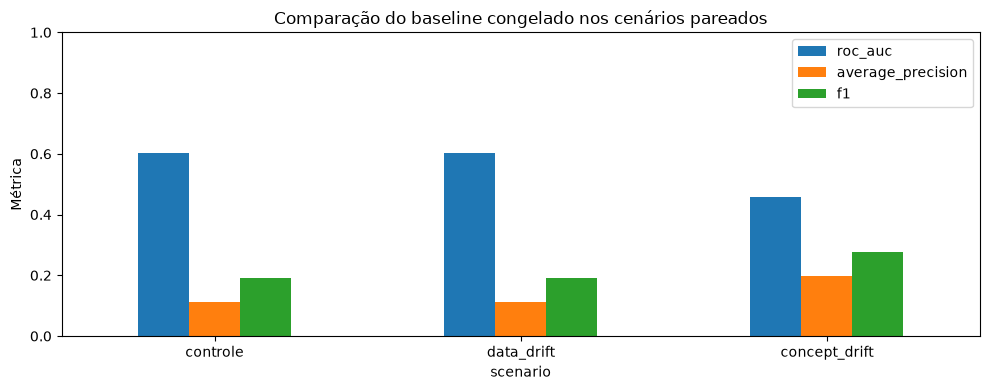

[Abrir relatório Evidently de controle](../data/processed/monitoring/20261009T130024072422Z/controle.html)

[Abrir relatório Evidently de data_drift](../data/processed/monitoring/20261009T130024072422Z/data_drift.html)

[Abrir relatório Evidently de concept_drift](../data/processed/monitoring/20261009T130024072422Z/concept_drift.html)

Execução MLflow: e737f5921d56441387377c3fbbcc8564
Artefatos: data/processed/monitoring/20261009T130024072422Z


,precision,recall,specificity,false_positive_rate,false_negative_rate,balanced_accuracy,matthews_correlation,brier_score,log_loss,true_positives,false_positives,false_negatives,true_negatives
scenario,,,,,,,,,,,,,
controle,0.1126,0.6037,0.5820,0.4180,0.3963,0.5929,0.1021,0.2389,0.6698,195,1537,128,2140
data_drift,0.1139,0.5697,0.6106,0.3894,0.4303,0.5901,0.1001,0.2314,0.6538,184,1432,139,2245
concept_drift,0.2073,0.4126,0.5613,0.4387,0.5874,0.4870,-0.0217,0.2593,0.7141,359,1373,511,1757


,scenario,class,precision,recall,f1,support
0,controle,0,0.943563,0.581996,0.719933,3677
1,controle,1,0.112587,0.603715,0.189781,323
2,data_drift,0,0.941695,0.610552,0.740802,3677
3,data_drift,1,0.113861,0.569659,0.189789,323
4,concept_drift,0,0.774691,0.561342,0.650982,3130
5,concept_drift,1,0.207275,0.412644,0.275942,870


In [8]:
display(
    drift_tables["data_drift"].sort_values(
        ["drift", "feature"], ascending=[False, True]
    )
)
summary[["roc_auc", "average_precision", "f1"]].plot.bar(figsize=(10, 4), rot=0)
plt.title("Comparação do baseline congelado nos cenários pareados")
plt.ylabel("Métrica")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

for name in scenarios:
    relative_path = (
        (execution_path / f"{name}.html").relative_to(project_root).as_posix()
    )
    display(Markdown(f"[Abrir relatório Evidently de {name}](../{relative_path})"))
print(f"Execução MLflow: {parent_run_id}")
print(f"Artefatos: {execution_path.relative_to(project_root)}")

display(
    summary[
        [
            "precision",
            "recall",
            "specificity",
            "false_positive_rate",
            "false_negative_rate",
            "balanced_accuracy",
            "matthews_correlation",
            "brier_score",
            "log_loss",
            "true_positives",
            "false_positives",
            "false_negatives",
            "true_negatives",
        ]
    ].round(4)
)
scenario_class_metrics = pd.concat(
    [
        report["by_class"].assign(scenario=name)
        for name, report in scenario_evaluations.items()
    ],
    ignore_index=True,
)
display(
    scenario_class_metrics[
        ["scenario", "class", "precision", "recall", "f1", "support"]
    ]
)

## 8 Estratégia de resposta operacional

| Sinal | Ação proposta | Evidência para encerrar a investigação |
| --- | --- | --- |
| Contrato inválido | Bloquear lote e solicitar correção à origem | Novo lote aprovado e causa registrada |
| Drift em renda ou crédito | Conferir coleta, unidades e mudança de perfil | Explicação da alteração e análise do impacto |
| Queda de desempenho | Investigar segmentos e novos desfechos | Comparação do baseline e de alternativas em avaliação independente |
| Falha de geração de relatório | Registrar falha operacional e reexecutar após correção | Relatório íntegro vinculado à execução |

Não retreinar nem promover automaticamente um modelo apenas porque existe
drift. Primeiro distinguir problema de coleta, mudança válida de população
e mudança na relação com o alvo. Definir responsável e prazo de análise na
documentação de operação. Medir latência por etapa e recursos da infraestrutura
é o próximo incremento de observabilidade.

Para abrir a interface do MLflow no mesmo ambiente Docker da demonstração,
execute na raiz do projeto:

```bash
docker compose --file docker/docker-compose.yml run --rm -p 5000:5000 notebook \
  mlflow ui --host 0.0.0.0 --port 5000 \
  --backend-store-uri sqlite:////app/data/processed/monitoring/mlflow.db
```

Acesse `http://localhost:5000`. Os artefatos locais usam os caminhos do
ambiente que os gerou; use a mesma montagem `/app` ao abrir execuções feitas
no container. Em execução local, use a URI do banco exibida pela configuração
deste notebook e mantenha o mesmo diretório do projeto.

## 9 Governança e causalidade para a entrega

O README deve consolidar decisões específicas deste experimento:

- Finalidade acadêmica, origem, condições de uso e limites dos dados.
- Tratamento do identificador como dado de rastreabilidade, sem incluí-lo no modelo.
- Avaliação de idade, escolaridade e demais possíveis proxies de discriminação.
- Plano de acesso e retenção para CSV, modelo, manifesto, logs e relatórios.
- Discussão fundamentada da base legal para o cenário de crédito e das diferenças
  entre um protótipo acadêmico e uma operação real, com fontes oficiais.
- Identificação dos rótulos sintéticos e dos limites de inferência causal.
- Procedimentos de revisão, resposta a incidentes e eventual atualização do modelo.

A hipótese de Data Drift é uma alteração simulada do perfil de renda e crédito.
A hipótese de Concept Drift é um choque de pagamento em um segmento, mantendo
as entradas observadas. Nenhum resultado comprova que esses eventos ocorreram
na população original. Não publicar dados individuais ou o manifesto de IDs
como evidência pública; preferir métricas agregadas e relatórios revisados.

## 10 O que foi demonstrado e o que falta entregar

| Requisito | Situação após executar os três notebooks |
| --- | --- |
| Conhecer a base e validar o recorte | Notebook 01 |
| Limpar, normalizar e treinar baseline | Notebook 02 |
| Contrato Pandera e bloqueio antes do modelo | Notebook 03 |
| Simular alteração de duas features | Notebook 03 |
| Evidently e relatórios HTML de drift | Notebook 03 |
| Concept Drift com rótulos sintéticos | Notebook 03 |
| Logs e rastreamento MLflow dos cenários | Notebook 03 |
| Saúde da infraestrutura e métricas por etapa | Completar antes da entrega final |
| README de arquitetura, governança e causalidade | Consolidar antes da entrega final |
| Scripts de execução e testes automatizados | Extrair e testar a lógica consolidada dos notebooks |
| Vídeo STAR de até cinco minutos | Gravar a demonstração final |

O vídeo deve mostrar: risco de degradação silenciosa; requisitos; lote
rejeitado, alterações e relatórios; resultados e resposta proposta.
Para reprodução, executar 01, 02 e 03 nessa ordem, sempre do início ao fim.
O checklist local de acompanhamento complementa a organização do trabalho;
as evidências e instruções de avaliação precisam estar na documentação entregue.